# EEE4022S Thesis Project: The development of a low-cost X-ray phantom for bone suppression and radiography system calibration

## By: M Saeed Solomon (SLMMOG032)

The pipeline on the three phantoms:

* **Prototype 2** (scanned 21 October): eggshell + plaster of Paris + water bone on a silicone-putty muscle layer with a thin candle-wax layer.
* **Prototype 3** (scanned 21 and 25 October): a resin cylinder in which CaCO$_3$ settled at the bone head and the head-shaft joint.
* **Final phantom** (scanned 25 October): an eggshell + plaster of Paris + water bone cast in a bottle-shaped resin + red food colouring body (muscle) inside a candle-wax layer (fat).

Steps: load the scans, register the high kVp scan onto the low kVp scan, find the ROIs, calibrate with the step wedge, suppress the bone, suppress the noise (Noise2Noise trained on the two prototypes and tested on the final phantom) and validate the final phantom.

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import pydicom
import os
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from Modules import Affine_matrix, Segmentation, Regions, Wedge_mask, Phantom_mask, Wedge_calibration, Bone_suppression, Denoising, Validation
from Modules.Bone_suppression import TREND

21 Oct low         : 060kVp_080mA_0.24mm_I112_water     60 kVp    80 mA
21 Oct high        : 120kVp_080mA_0.24mm_I113_water    120 kVp    80 mA
21 Oct repeat_low  : 060kVp_080mA_0.24mm_I106           60 kVp    80 mA
21 Oct repeat_high : 120kVp_080mA_0.24mm_I108          120 kVp    80 mA


25 Oct low         : 060kVp_080mA_0.24mm_I21369         60 kVp    80 mA
25 Oct high        : 120kVp_080mA_0.24mm_I21371        120 kVp    80 mA
25 Oct repeat_low  : 060kVp_080mA_0.24mm_I21370         60 kVp    80 mA
25 Oct repeat_high : 120kVp_080mA_0.24mm_I21372        120 kVp    80 mA


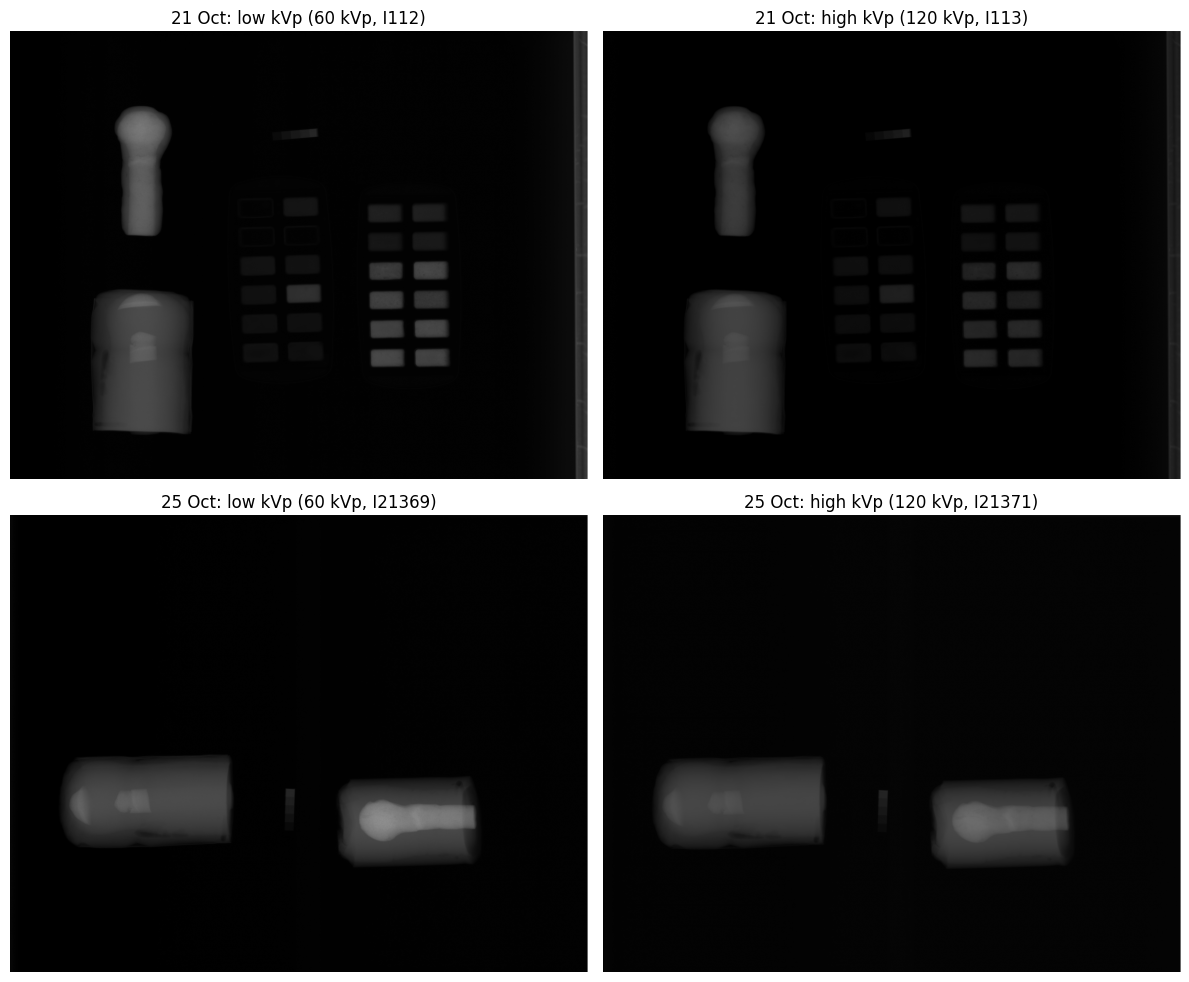

In [2]:
# ========================================================================================================

# Phase 1: Import Images

"""Two scan sessions, each with a low (60 kVp) and a high (120 kVp) kVp scan at 80 mA, and a repeat of both (the second,
independent noisy image that Noise2Noise needs in Phase 6).
* 21 October 2026: both ice trays with the PLA step wedge above them, prototype 2 (upper left) and prototype 3 (lower left).
* 25 October 2026: prototype 3 (left), the step wedge (middle) and the final phantom (right), lying along the rows with the
  bone heads on the left.
Scans tagged with SKIP are not used (open background clipped, or phantoms turned 90 degrees with no 120 kVp partner)."""

pixel_spacing = 0.24            # mm, common pixel spacing for all scans
SKIP = ('bg-saturated', 'vertical')
SESSIONS = {
    '21 Oct': dict(folder='../Lodox Statscan Images/Scans', prefix='2026-10-21_trays-phantoms_',
                   low='060kVp_080mA_0.24mm_I112_water', high='120kVp_080mA_0.24mm_I113_water',
                   repeat_low='060kVp_080mA_0.24mm_I106', repeat_high='120kVp_080mA_0.24mm_I108'),
    '25 Oct': dict(folder='../Lodox Statscan Images/Final Phantom Scans', prefix='2026-10-25_phantoms_',
                   low='060kVp_080mA_0.24mm_I21369', high='120kVp_080mA_0.24mm_I21371',
                   repeat_low='060kVp_080mA_0.24mm_I21370', repeat_high='120kVp_080mA_0.24mm_I21372'),
}

# Function to bring a scan to the common pixel spacing by averaging blocks of pixels
def match_spacing(image, spacing):
    data_set = image.pixel_array.astype(float)
    data_set[:, -1] = data_set[:, -2]       # the last column is a marker at the preset's maximum grey level, not image data
    factor = int(round(spacing / float(image.ImagerPixelSpacing[0])))     # e.g. 0.24 / 0.12 = 2 for I110 (rest are 1)
    return Affine_matrix.downsample(data_set, factor)


# Function to repeat normalizing image
def ready_img(data_set):
    if data_set.ndim == 3:
        data_set = data_set[..., 0]  # to ensure the image dimensions are only 2D
    return (data_set - data_set.min()) / (data_set.max() - data_set.min())


# The scans of a session can differ in size (scan length, the 0.12 mm I110 scan of 21 October), so every scan is brought
# to the common pixel spacing and cropped to the smallest shape in its session (read from the headers of all its scans).
# Every scan starts at the top, so only excess background at the bottom/right is removed.
sessions = {}
for session, cfg in SESSIONS.items():
    files = sorted(f for f in os.listdir(cfg['folder']) if f.lower().endswith('.dcm') and not any(s in f for s in SKIP))
    headers = [pydicom.dcmread(os.path.join(cfg['folder'], f), stop_before_pixels=True) for f in files]
    factor = [int(round(pixel_spacing / float(ds.ImagerPixelSpacing[0]))) for ds in headers]
    rows = min(ds.Rows // k for ds, k in zip(headers, factor))
    cols = min(ds.Columns // k for ds, k in zip(headers, factor))
    scans = {key: pydicom.dcmread(os.path.join(cfg['folder'], cfg['prefix'] + cfg[key] + '.dcm'))
             for key in ('low', 'high', 'repeat_low', 'repeat_high')}
    images = {key: match_spacing(ds, pixel_spacing)[:rows, :cols] for key, ds in scans.items()}
    sessions[session] = dict(scans=scans, images=images, target=ready_img(images['low']),
                             misaligned=ready_img(images['high']))
    for key, ds in scans.items():
        print(f"{session} {key:12s}: {cfg[key]:32s} {float(ds.KVP):4.0f} kVp  {float(ds.XRayTubeCurrent):4.0f} mA")

output_folder = os.path.join('./outputs', '+'.join(f"I{s['scans']['low'].InstanceNumber}_I{s['scans']['high'].InstanceNumber}"
                                                   for s in sessions.values()))
os.makedirs(output_folder, exist_ok=True)

# Display initial images
fig, axes = plt.subplots(len(sessions), 2, figsize=(12, 5 * len(sessions)))
for row, (session, s) in zip(axes, sessions.items()):
    for ax, key in zip(row, ('low', 'high')):
        ax.imshow(ready_img(s['images'][key]), cmap="gray")
        ax.set_title(f"{session}: {key} kVp ({s['scans'][key].KVP} kVp, I{s['scans'][key].InstanceNumber})")
        ax.axis("off")
plt.tight_layout()
plt.show()

## Pre-Processing

Despite the aim of thesis being to use the developed phantom for bone suppression, one cannot simply assume the phantom will not move
between subsequent scans. This could be due to the phantom being manually moved, slight shifts caused by bumping into the scanner or simply
as a result of the scanner's vibrations.

Every frame holds its objects in fixed places, so each object gets a fixed box (Modules/Regions.py, SESSION_BOXES_MM) and is processed on its
own from here on: on 21 October the trays with the step wedge, prototype 2 and prototype 3; on 25 October the step wedge, prototype 3 and the
final phantom. The objects are found with Otsu thresholding of the smoothed target, and each box is checked to hold what it should, so an
object that has moved out of its box stops the pipeline here instead of giving wrong measurements.

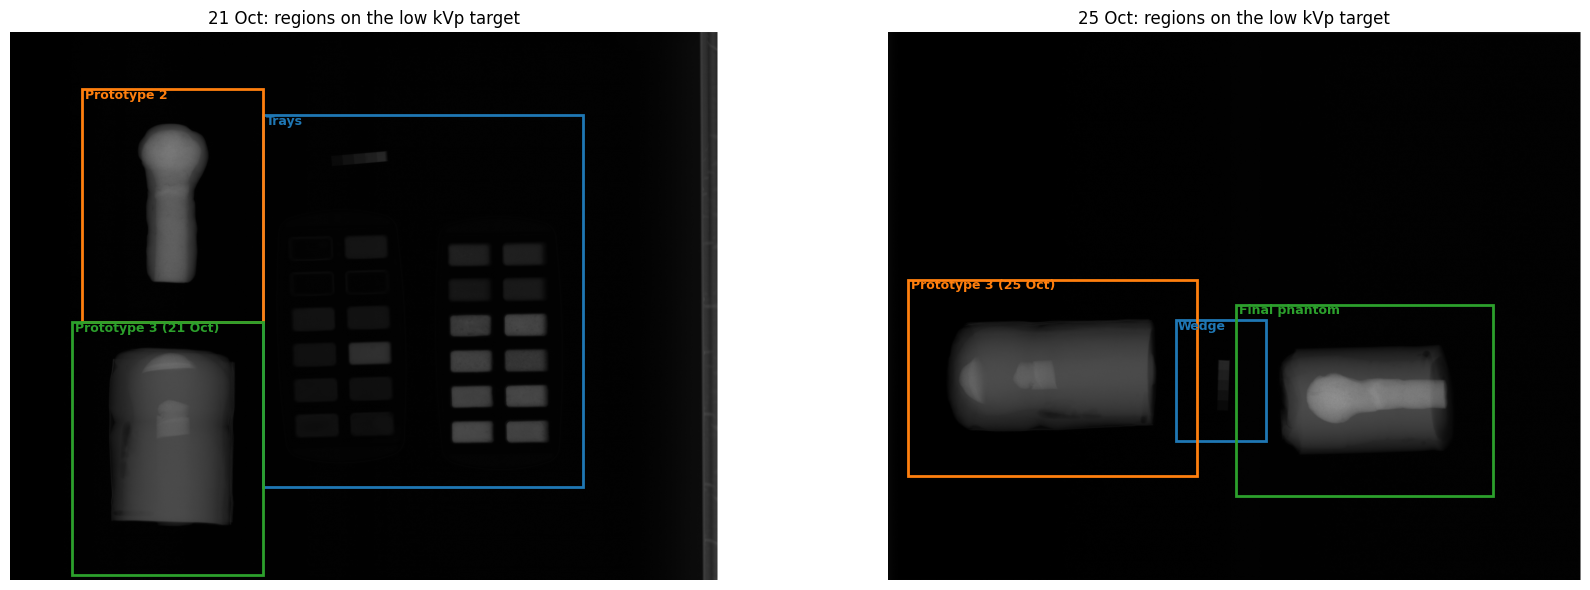

Trays: rotated -0.004 degrees, shifted (-0.31, 1.48) px


Prototype 2: rotated 0.000 degrees, shifted (0.00, 1.59) px


Prototype 3 (21 Oct): rotated 0.000 degrees, shifted (0.00, 1.54) px


Wedge: rotated 0.000 degrees, shifted (0.00, 7.19) px


Prototype 3 (25 Oct): rotated 0.006 degrees, shifted (0.05, 7.35) px


Final phantom: rotated -0.007 degrees, shifted (0.10, 7.32) px


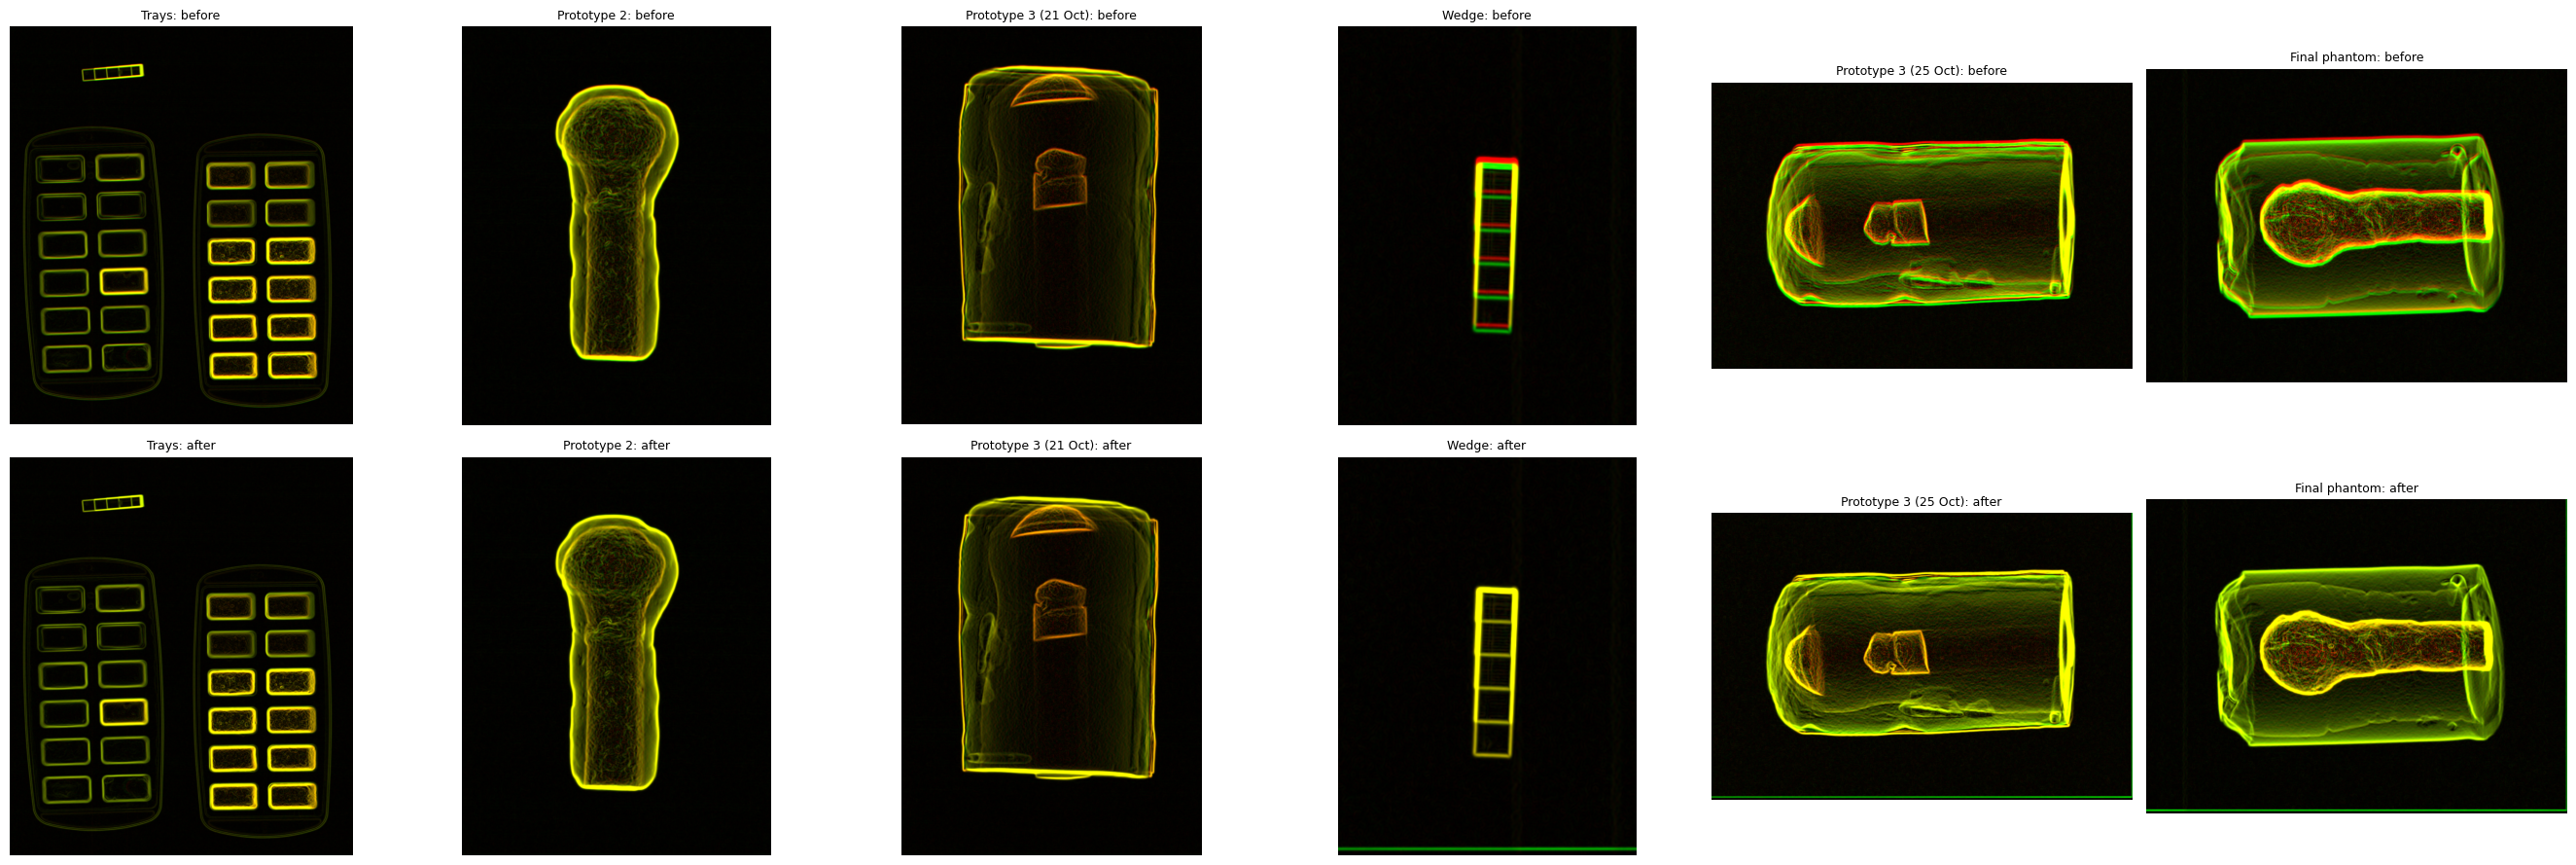

In [3]:
# ========================================================================================================

# Phase 2: Pre-processing


# Regions of every session; from here on each region is known by its name alone (region_session gives its session)
regions, region_session = {}, {}
fig, axes = plt.subplots(1, len(sessions), figsize=(9 * len(sessions), 6))
for ax, (session, s) in zip(axes, sessions.items()):
    threshold = Segmentation.otsu_threshold(Segmentation.smooth(s['target'], pixel_spacing), passes=2)
    session_regions = Regions.split(s['target'], threshold, pixel_spacing, Regions.SESSION_BOXES_MM[session])
    Regions.show_regions(s['target'], session_regions, pixel_spacing, ax=ax, title=f'{session}: regions on the low kVp target')
    for name, region in session_regions.items():
        regions[name], region_session[name] = region, session
plt.tight_layout()
plt.show()

"""Therefore it is important to align the images before any further processing. This is done by finding the rotation and shift
that minimise the mean squared error (MSE) between the target and the misaligned image, region by region. The two images are
taken at different kVp, so their grey levels differ: the bone, the soft tissue and the background each change contrast by a
different amount, and the MSE of the raw images can settle half a pixel to a pixel away from the true position. A pixel of
misalignment leaves a bright and dark fringe along every edge of the subtracted image. The edges themselves sit in the same
place at both kVp, so the MSE is taken between the edge (gradient magnitude) images instead (Affine_matrix.register_edges).
The search runs on 4x downsampled images first and is then refined at full resolution."""

targets, aligned = {}, {}
for name, region in regions.items():
    s = sessions[region_session[name]]
    targets[name] = region.crop(s['target'])
    moving = region.crop(s['misaligned'])
    (theta_opt, tx_opt, ty_opt), result = Affine_matrix.register_edges(targets[name], moving, [0, 0, 0])
    aligned[name] = Affine_matrix.transformation(moving, theta_opt, tx_opt, ty_opt)
    print(f"{name}: rotated {theta_opt:.3f} degrees, shifted ({tx_opt:.2f}, {ty_opt:.2f}) px")

# Overlays of the edges before (top) and after (bottom) registration: red = low kVp, green = high kVp, yellow = both
fig, axes = plt.subplots(2, len(regions), figsize=(4.5 * len(regions), 9))
for k, (name, region) in enumerate(regions.items()):
    moving = region.crop(sessions[region_session[name]]['misaligned'])
    for ax, image, title in [(axes[0, k], moving, 'before'), (axes[1, k], aligned[name], 'after')]:
        overlay = np.stack([Affine_matrix.edges(targets[name]), Affine_matrix.edges(image), np.zeros_like(image)], axis=-1)
        ax.imshow(np.clip(3 * overlay, 0, 1))
        ax.set_title(f'{name}: {title}', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Region of Interest

Otsu thresholding was used previously to identify the different structures and the step wedge which is present in every image for the reference wedge calibration in the following sections. The ROIs are saved in arrays for processing later.

Estimated fat layer thickness: 2.9 mm (pass fat_thickness_mm to override)


Fat and muscle from the spectral contrast: pure-fat rays reach up to 13.4 mm inside the outline (95th percentile)


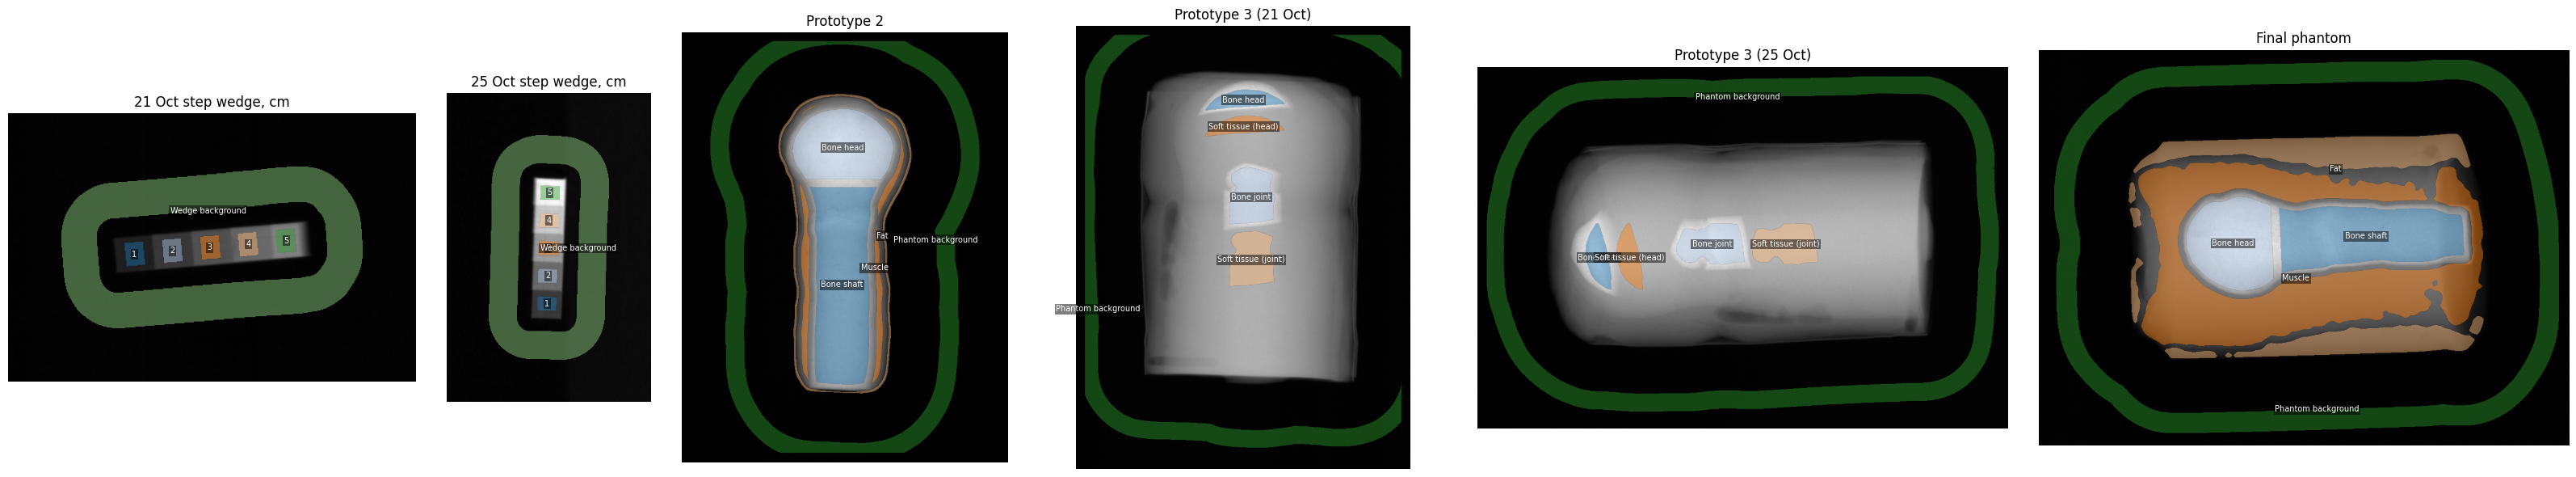

In [4]:
# ========================================================================================================

# Phase 3: Region of Interest

"""The masks are found on the target (low kVp) crop of each region; the high kVp crop was registered onto it in Phase 2, so the
same masks line up with the aligned crop.
* Step wedge: one ROI per step and a background band (in the trays box on 21 October, in its own box on 25 October).
* Prototype 2: bone split into the shaft and the head where it widens, the silicone muscle around it and the thin
  candle-wax fat layer (estimated from the image).
* Prototype 3: the CaCO3 settled at the head and the head-shaft joint, so bone ROIs are only placed there, each with a
  soft-tissue reference moved along the cylinder's axis (same path length through the cylinder). On 25 October the
  cylinder lies along the rows (axis='horizontal').
* Final phantom: bone (shaft and head) inside the bottle-shaped resin body (muscle) inside the candle wax (fat). The wax is
  thin around the wide base of the resin, at the bone head, and thick around the narrow middle, so it cannot be a band of one
  thickness, and in a cylinder the grey level falls towards the edge for any material. The low over the high kVp contrast
  follows the material instead of the path length (it is lower in wax than in resin), so every soft-tissue pixel is called
  fat or muscle from it (Phantom_mask.fat_and_muscle); the rays that cross both layers are left out."""

wedge_box = {'21 Oct': 'Trays', '25 Oct': 'Wedge'}                 # the region that holds each session's wedge
wedges = {session: Wedge_mask.Wedge_Mask(targets[box], regions[box].labels, regions[box].objects, pixel_spacing)
          for session, box in wedge_box.items()}

masks = {'Prototype 2': Phantom_mask.Phantom_Mask(targets['Prototype 2'], regions['Prototype 2'].labels,
                                                  regions['Prototype 2'].objects, pixel_spacing, soft_tissue=True)}
for session, axis in [('21 Oct', 'vertical'), ('25 Oct', 'horizontal')]:
    name = f'Prototype 3 ({session})'
    masks[name] = Phantom_mask.Final_Phantom_Mask(targets[name], regions[name].labels, regions[name].objects,
                                                  pixel_spacing, axis=axis)

# Final phantom: spectral contrast = low / high kVp contrast, each against the open field more than 30 mm from any object
name = 'Final phantom'
open_field = ndi.distance_transform_edt(regions[name].labels == 0) * pixel_spacing > 30
contrast = {k: Segmentation.smooth(img[name] - np.median(img[name][open_field]), pixel_spacing)
            for k, img in [('low', targets), ('high', aligned)]}
noise_high = Segmentation.background_noise(contrast['high'][open_field])[1]
spectral = np.divide(contrast['low'], contrast['high'], out=np.zeros_like(contrast['low']),
                     where=contrast['high'] > 6 * noise_high)
masks[name] = Phantom_mask.Phantom_Mask(targets[name], regions[name].labels, regions[name].objects, pixel_spacing,
                                        soft_tissue=True, fat_contrast=spectral)
final = masks[name]

# ROI validation (flowchart): the checks inside each mask class must pass before the ROIs are used
for name, mask in list(wedges.items()) + list(masks.items()):
    if not mask.valid:
        print(f"ROI validation failed for {name}: check the overlays below before using these ROIs")

# Masks over the low kVp crops (the same masks line up with the aligned high kVp crops)
fig, axes = plt.subplots(1, 6, figsize=(32, 6), gridspec_kw={'width_ratios': [1, 0.5, 0.8, 1, 1.3, 1.3]})
for ax, (session, wedge) in zip(axes[:2], wedges.items()):
    wedge.show(targets[wedge_box[session]], ax=ax, title=f'{session} step wedge, cm')
for ax, (name, mask) in zip(axes[2:], masks.items()):
    mask.show(targets[name], ax=ax, title=name)
plt.tight_layout()
plt.show()

# Save the ROIs: one label array per region (0 = no ROI, k = roi_names[k - 1])
for name, mask in [(wedge_box[s], w) for s, w in wedges.items()] + list(masks.items()):
    np.savez_compressed(os.path.join(output_folder, f"roi_mask_{name.replace(' ', '_')}.npz"), roi_mask=mask.mask,
                        roi_names=np.array(mask.names), box_mm=np.array(regions[name].box_mm))

## Wedge Calibration

The two presets have different grey-level gains, so the step wedge in every frame is used as a common reference: its five steps (1-5 cm of PLA) give the grey level per cm of PLA at each kVp, and every phantom image becomes a thickness map $T$ in cm of PLA. The subtraction weight $w$ is then a ratio of PLA-equivalent thicknesses, comparable between the presets and the sessions.

21 Oct, low kVp (60 kVp): C(t) = 0.03126 t + -0.0005794 t^2 (rms residual 0.001); straight line C = 0.02889 t (rms residual 0.0022); rises across 0-5 cm
21 Oct, high kVp (120 kVp): C(t) = 0.02691 t + -0.000336 t^2 (rms residual 0.00039); straight line C = 0.02554 t (rms residual 0.0012); rises across 0-5 cm
25 Oct, low kVp (60 kVp): C(t) = 0.03158 t + -0.000628 t^2 (rms residual 0.00015); straight line C = 0.02901 t (rms residual 0.0022); rises across 0-5 cm
25 Oct, high kVp (120 kVp): C(t) = 0.02576 t + -0.0002573 t^2 (rms residual 0.00028); straight line C = 0.02471 t (rms residual 0.00092); rises across 0-5 cm


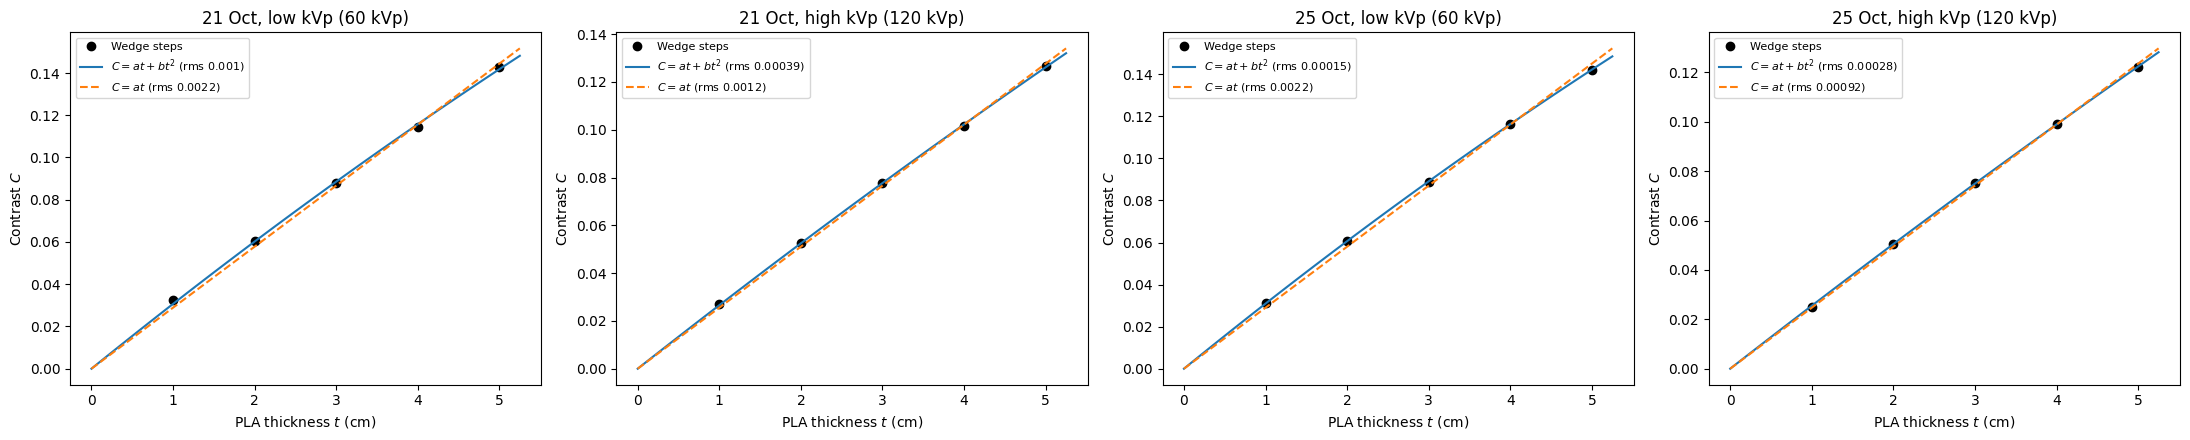

In [5]:
# ========================================================================================================

# Phase 4: Wedge Calibration

"""Each step's contrast is C_k = median(step k) - median(wedge background), t_k = k cm. A straight line through the origin,
C = a t, gives the gain a of each preset (a quadratic C = a t + b t^2 is fitted alongside it to show the curvature over the
wedge). The phantoms are thicker than the wedge, so their maps use the straight line, T = (image - background) / a, with the
background band next to each phantom (the images are unfiltered log images, so the gain holds beyond the wedge)."""

kvp = {session: (float(s['scans']['low'].KVP), float(s['scans']['high'].KVP)) for session, s in sessions.items()}
calibration = {session: {k: Wedge_calibration.Wedge_Calibration(img[box], wedges[session],
                                                                f'{session}, {k} kVp ({kvp[session][i]:.0f} kVp)')
                         for i, (k, img) in enumerate([('low', targets), ('high', aligned)])}
               for session, box in wedge_box.items()}
for cal in (c for session in calibration.values() for c in session.values()):
    print(cal.summary())

thickness_maps = {name: {k: calibration[region_session[name]][k].linear_thickness_map(
                             img[name], np.median(img[name][mask.roi('Phantom background')]))
                         for k, img in [('low', targets), ('high', aligned)]}
                  for name, mask in masks.items()}

fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, cal in zip(axes, (c for session in calibration.values() for c in session.values())):
    cal.show(ax)
plt.tight_layout()
plt.show()

## Bone Suppression

Weighted log subtraction, $S = T_H - w\,T_L$. The weight is swept from 0 to $2w_{bone}$ and $w_{opt}$ is the weight at which the bone's signature disappears from $S$.

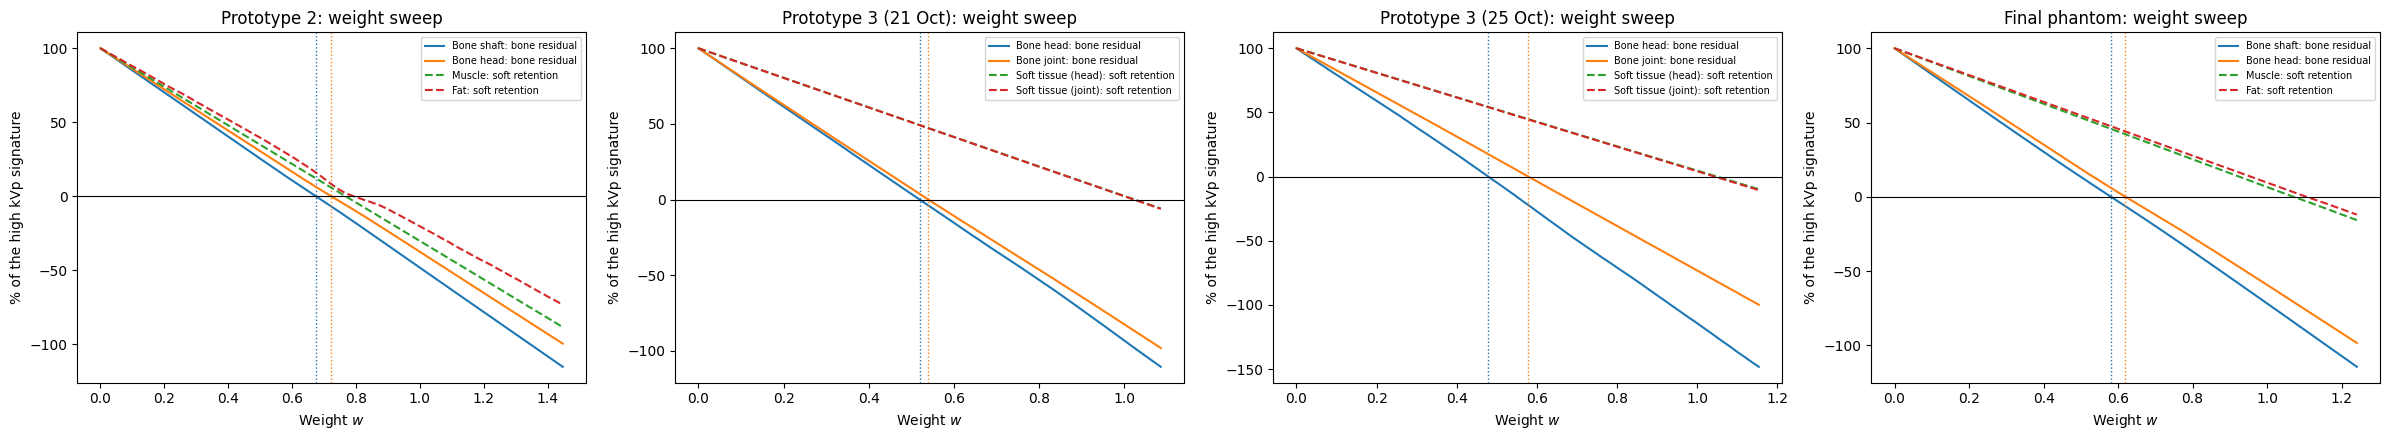

,phantom,b_L,b_H,w_opt,soft_retention_pct
ROI,,,,,
Bone shaft,Prototype 2,5.558,3.728,0.675,12.078
Bone head,Prototype 2,7.531,5.451,0.723,5.818
Bone head,Prototype 3 (21 Oct),2.960,1.521,0.520,49.165
Bone joint,Prototype 3 (21 Oct),2.352,1.278,0.540,47.184
Bone head,Prototype 3 (25 Oct),2.344,1.112,0.479,54.303
Bone joint,Prototype 3 (25 Oct),2.507,1.447,0.579,44.497
Bone shaft,Final phantom,6.490,3.716,0.581,45.730
Bone head,Final phantom,6.919,4.293,0.620,42.110


Final phantom, one weight: bone left in S Bone shaft -3.2 %, Bone head +2.9 %
Final phantom, per-part weights: bone left in S Bone shaft -0.1 %, Bone head +0.0 %


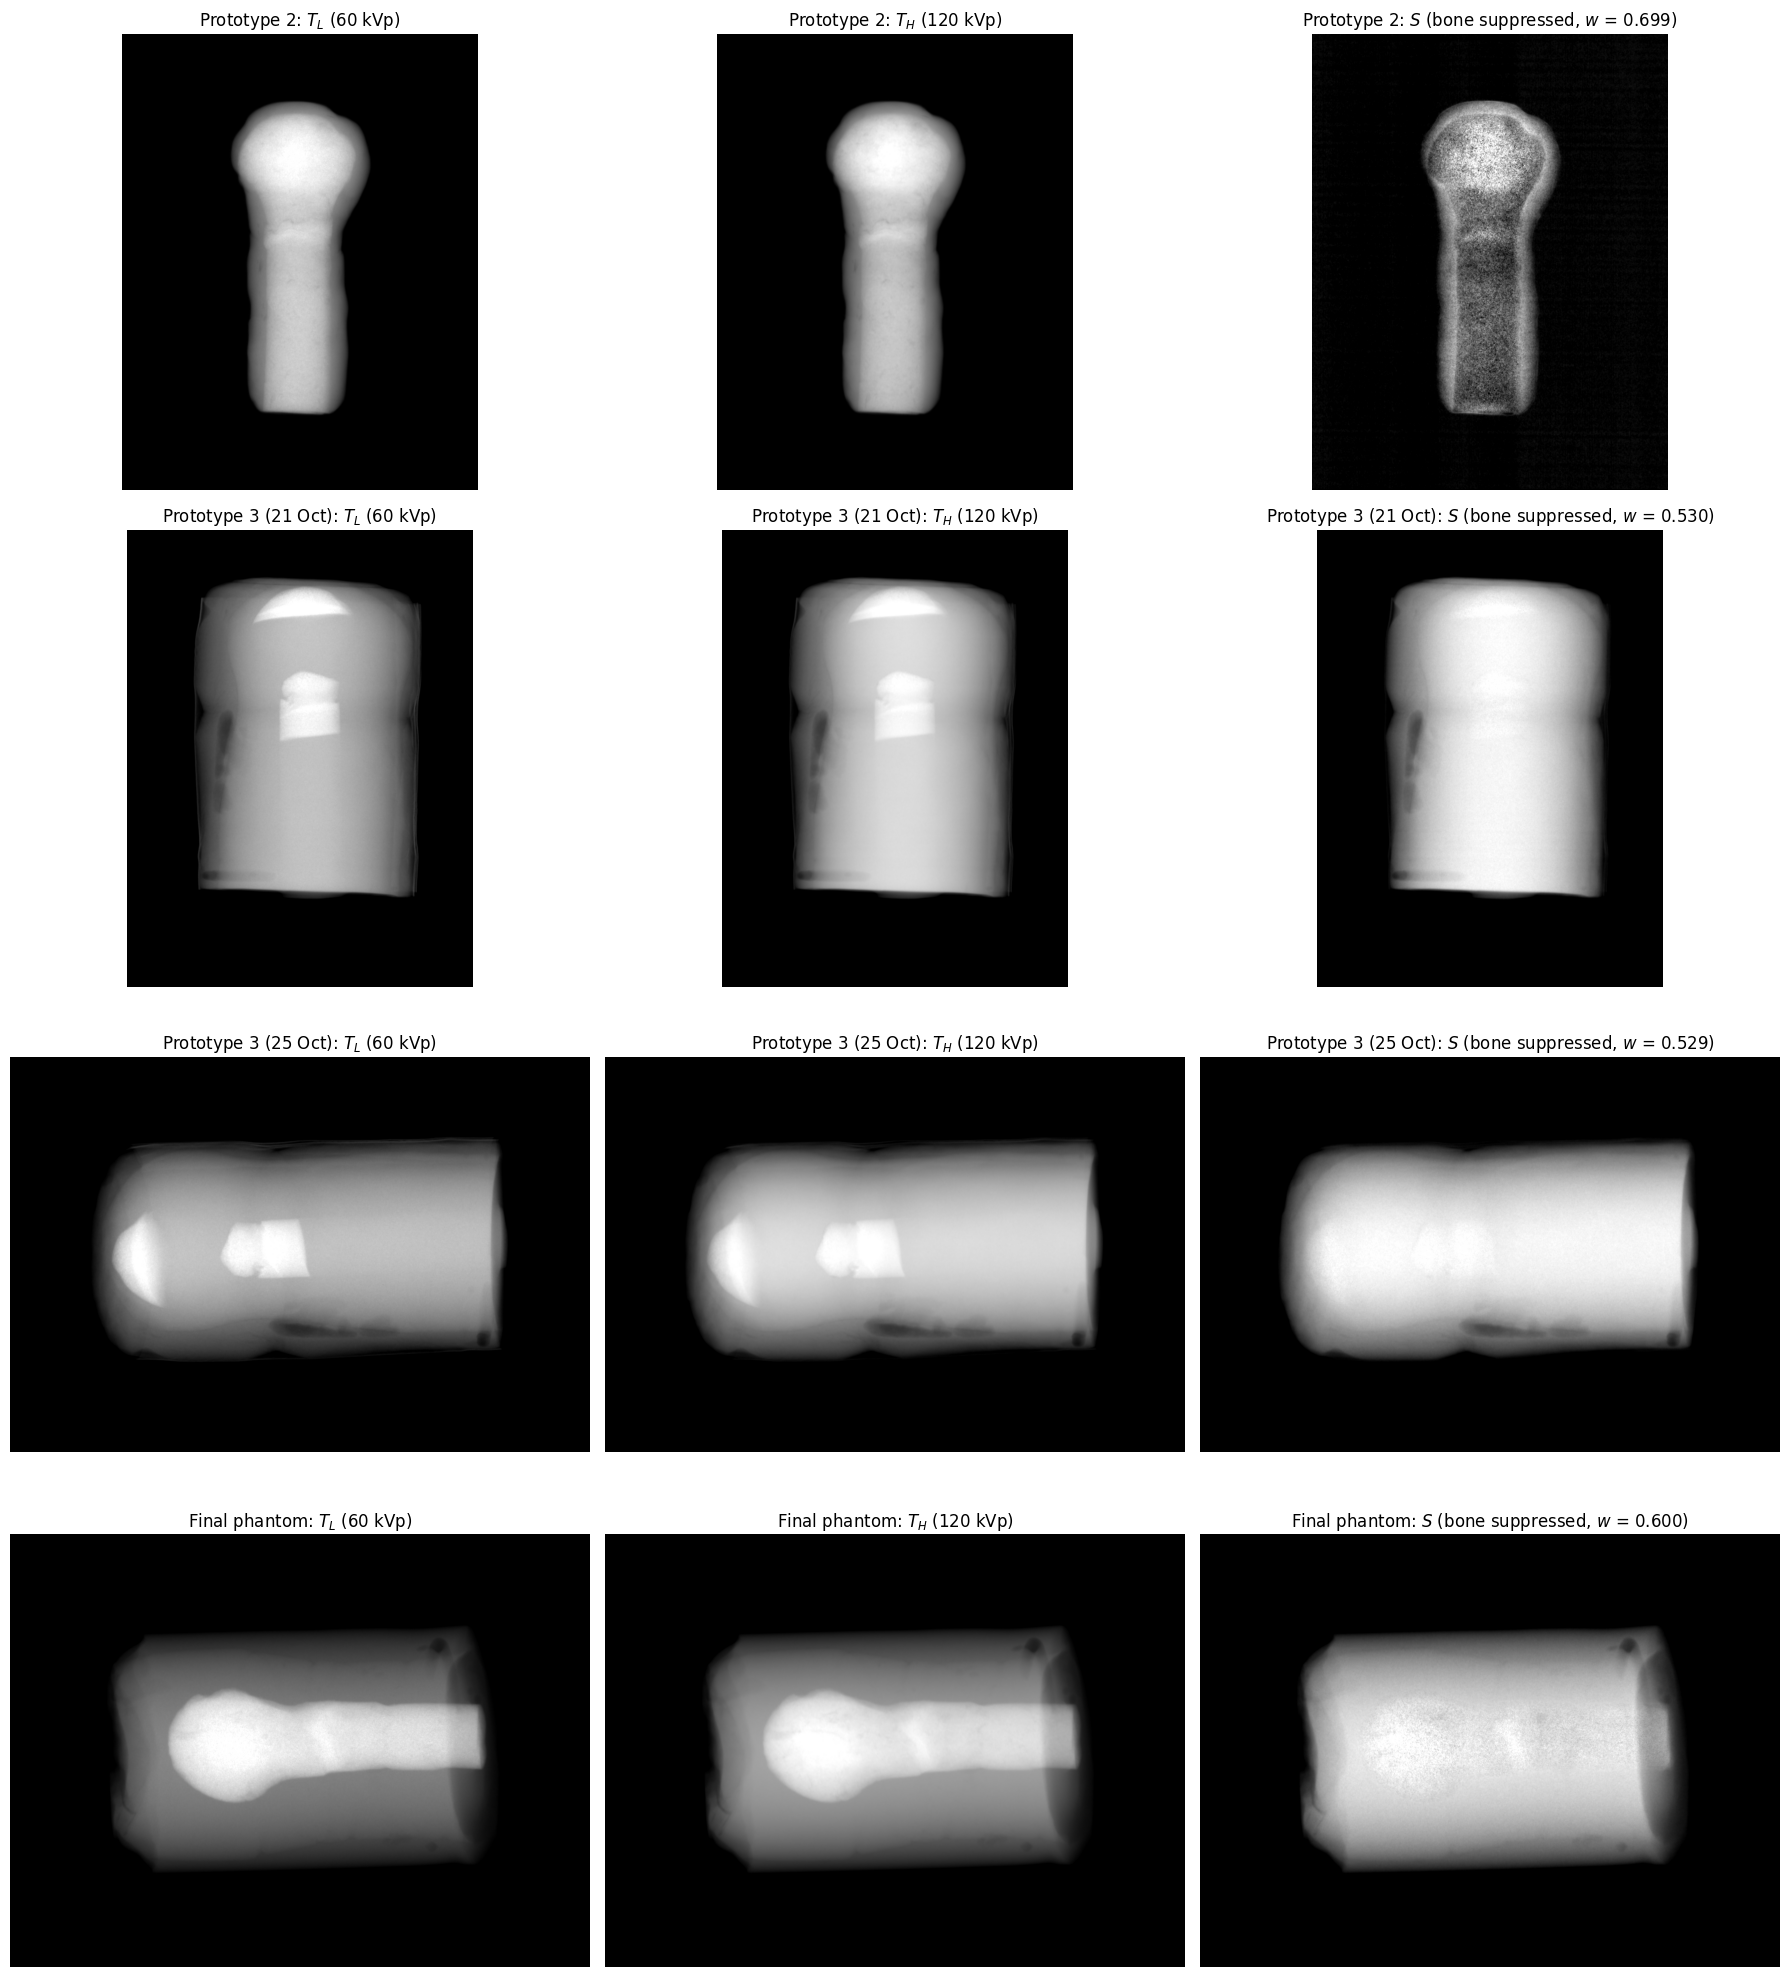

In [6]:
# ========================================================================================================

# Phase 5: Bone Suppression

"""Weighted log subtraction (Modules/Bone_suppression.py) on the thickness maps: S = T_H - w T_L.
Bone signature b = median of the bone ROI - its reference, soft-tissue signature s = soft-tissue ROI - background, both
before subtraction. The sweep runs w from 0 to 2 w_bone (w_bone = b_H / b_L) in 201 steps and measures the bone residual
(bone signature of S / b_H) and the soft tissue kept (soft-tissue signature of S / s_H) at every step; w_opt is where the
bone residual crosses zero.
* Prototype 2: the bone against the silicone muscle around it.
* Prototype 3: the settled CaCO3 against the soft tissue at the same path length through the cylinder.
* Final phantom: the bone sits on the axis of a cylinder, where the soft tissue path is longer than beside the bone, so the
  bone is measured against the soft tissue interpolated under it (TREND: a quadratic across the bone fitted to the muscle on
  both sides, column by column; Phantom_Mask.soft_tissue_trend)."""

bg = 'Phantom background'
prototype_3 = dict(bones={'Bone head': 'Soft tissue (head)', 'Bone joint': 'Soft tissue (joint)'},
                   soft={'Soft tissue (head)': bg, 'Soft tissue (joint)': bg})
phantoms = {
    'Prototype 2': dict(bones={'Bone shaft': 'Muscle', 'Bone head': 'Muscle'}, soft={'Muscle': bg, 'Fat': bg}),
    'Prototype 3 (21 Oct)': prototype_3,
    'Prototype 3 (25 Oct)': prototype_3,
    'Final phantom': dict(bones={'Bone shaft': TREND, 'Bone head': TREND}, soft={'Muscle': bg, 'Fat': bg},
                          trend=final.soft_tissue_trend, retention_of={'Bone shaft': 'Muscle', 'Bone head': 'Muscle'}),
}

sweeps, results = {}, []
fig, axes = plt.subplots(1, len(phantoms), figsize=(6 * len(phantoms), 4.5))
for ax, (name, p) in zip(axes, phantoms.items()):
    T = thickness_maps[name]
    sweeps[name] = Bone_suppression.Weight_Sweep(T['low'], T['high'], masks[name], p['bones'], p['soft'], label=name,
                                                 trend=p.get('trend'))
    sweeps[name].show(ax)
    df = sweeps[name].summary(p.get('retention_of'))           # final phantom: the muscle kept at w_opt
    df.insert(0, 'phantom', name)
    results.append(df)
plt.tight_layout()
plt.show()

results = pd.concat(results)
display(results[['phantom', 'b_L', 'b_H', 'w_opt', 'soft_retention_pct']].round(3))
results.to_csv(os.path.join(output_folder, 'weight_sweep.csv'))

"""One weight per phantom, the mean w_opt of its bone ROIs, except for the final phantom. Its head and shaft cancel at
different weights at every bone thickness (so this is not beam hardening; prototype 2, with the same bone mixture, shows the
same), and one weight leaves part of the bone in each of them. Its bone is therefore removed part by part: the soft tissue
is subtracted at the mean weight everywhere, and the bone's own contribution, B_L = T_L - trend(T_L), at the weight of its
part (blended over 10 mm at the head-shaft junction): S = T_H - w T_L - (w_part - w) B_L (Weight_Sweep.subtract_parts)."""

suppressed = {}                                                 # {phantom: {'S': image, 'w': weight[, 'w_part': map]}}
for name, sweep in sweeps.items():
    w = np.mean(list(sweep.w_opt.values()))
    S = sweep.subtract(w)
    suppressed[name] = {'w': w}
    if name == 'Final phantom':
        blend = 5 / pixel_spacing
        w_part = np.interp(final.along_axis(), [final.split_s - blend, final.split_s + blend],
                           [sweep.w_opt['Bone shaft'], sweep.w_opt['Bone head']])
        S_single = S
        S = sweep.subtract_parts(w, w_part, ndi.binary_dilation(final.bone, iterations=int(round(1 / pixel_spacing))))
        for label, image in [('one weight', S_single), ('per-part weights', S)]:
            residual = {r: 100 * sweep.bone_contrast(image, r) / sweep.b_high[r] for r in sweep.bones}
            print(f"Final phantom, {label}: bone left in S " + ', '.join(f'{r} {v:+.1f} %' for r, v in residual.items()))
        suppressed[name]['w_part'] = w_part
    suppressed[name]['S'] = S
    np.savez_compressed(os.path.join(output_folder, f"suppressed_{name.replace(' ', '_').replace('(', '').replace(')', '')}.npz"),
                        S=S, w=w, T_low=sweep.T_low, T_high=sweep.T_high)

fig, axes = plt.subplots(len(suppressed), 3, figsize=(18, 5 * len(suppressed)))
for row, (name, s) in zip(axes, suppressed.items()):
    inside = masks[name].footprint
    for ax, image, title in zip(row, [sweeps[name].T_low, sweeps[name].T_high, s['S']],
                                ['$T_L$ (60 kVp)', '$T_H$ (120 kVp)', f'$S$ (bone suppressed, $w$ = {s["w"]:.3f})']):
        vmin, vmax = np.percentile(image[inside], [1, 99])
        ax.imshow(image, cmap='gray', vmin=vmin, vmax=vmax)
        ax.set_title(f'{name}: {title}')
        ax.axis('off')
plt.tight_layout()
plt.show()

## Denoising

Image subtraction introduces its own noise into images affectin the SNR and CNR of the image. This section aims to apply classical and denoising filters to enhance the final bone suppressed images. Noise2Noise is trained on the two prototypes and tested on the final phantom, which it never sees during training.

Prototype 2: rho_x = 0.62, rho_y = 0.74 -> Noise2Noise
Prototype 3 (21 Oct): rho_x = 0.65, rho_y = 0.76 -> Noise2Noise
Prototype 3 (25 Oct): rho_x = 0.65, rho_y = 0.72 -> Noise2Noise
Final phantom: rho_x = 0.65, rho_y = 0.73 -> Noise2Noise


Noise2Noise network loaded from ./outputs\I112_I113+I21369_I21371\noise2noise.pt


role  max_abs_delta_mu  \
phantom              filter                                              
Prototype 2          Gaussian           N2N training             0.012   
                     Median             N2N training             0.009   
                     Bilateral          N2N training             0.008   
                     Non-local means    N2N training             0.001   
                     Noise2Noise        N2N training             0.014   
Prototype 3 (21 Oct) Gaussian           N2N training             0.008   
                     Median             N2N training             0.005   
                     Bilateral          N2N training             0.005   
                     Non-local means    N2N training             0.001   
                     Noise2Noise        N2N training             0.007   
Prototype 3 (25 Oct) Gaussian         N2N validation             0.007   
                     Median           N2N validation             0.003   
                     Bilateral        N2N validation             0.004   
                     Non-local means  N2N validation             0.006   
                     Noise2Noise      N2N validation             0.009   
Final phantom        Gaussian               N2N test             0.024   
                     Median                 N2N test             0.020   
                     Bilateral              N2N test             0.003   
                     Non-local means        N2N test             0.002   
                     Noise2Noise            N2N test             0.028   

                                      noise_reduction_pct  edge_change_mm  
phantom              filter                                                
Prototype 2          Gaussian                      27.929           0.182  
                     Median                        17.705           0.013  
                     Bilateral                     29.761          -0.095  
                     Non-local means               33.419          -0.016  
                     Noise2Noise                   34.735           0.076  
Prototype 3 (21 Oct) Gaussian                      27.313           0.092  
                     Median                        17.097          -0.004  
                     Bilateral                     27.623          -0.022  
                     Non-local means               33.060          -0.002  
                     Noise2Noise                   34.960          -0.012  
Prototype 3 (25 Oct) Gaussian                       4.079           0.009  
                     Median                         2.728          -0.000  
                     Bilateral                      4.854          -0.019  
                     Non-local means                4.758           0.001  
                     Noise2Noise                    4.807           0.003  
Final phantom        Gaussian                      16.662           0.039  
                     Median                        10.741           0.000  
                     Bilateral                     16.745          -0.021  
                     Non-local means               19.823          -0.000  
                     Noise2Noise                   20.281          -0.002

Test on the final phantom: RMS difference to its independent repeat scan (lower is better):


,"RMS difference to S2, bone (cm PLA)","RMS difference to S2, soft tissue (cm PLA)","reduction, bone (%)","reduction, soft tissue (%)"
filter,,,,
S (unfiltered),0.1955,0.0450,0.0000,0.0000
Gaussian,0.1318,0.0351,32.5516,21.8699
Median,0.1464,0.0380,25.1096,15.4569
Bilateral,0.1871,0.0440,4.2753,2.2596
Non-local means,0.1955,0.0393,0.0052,12.6543
Noise2Noise,0.1335,0.0342,31.6854,23.8902


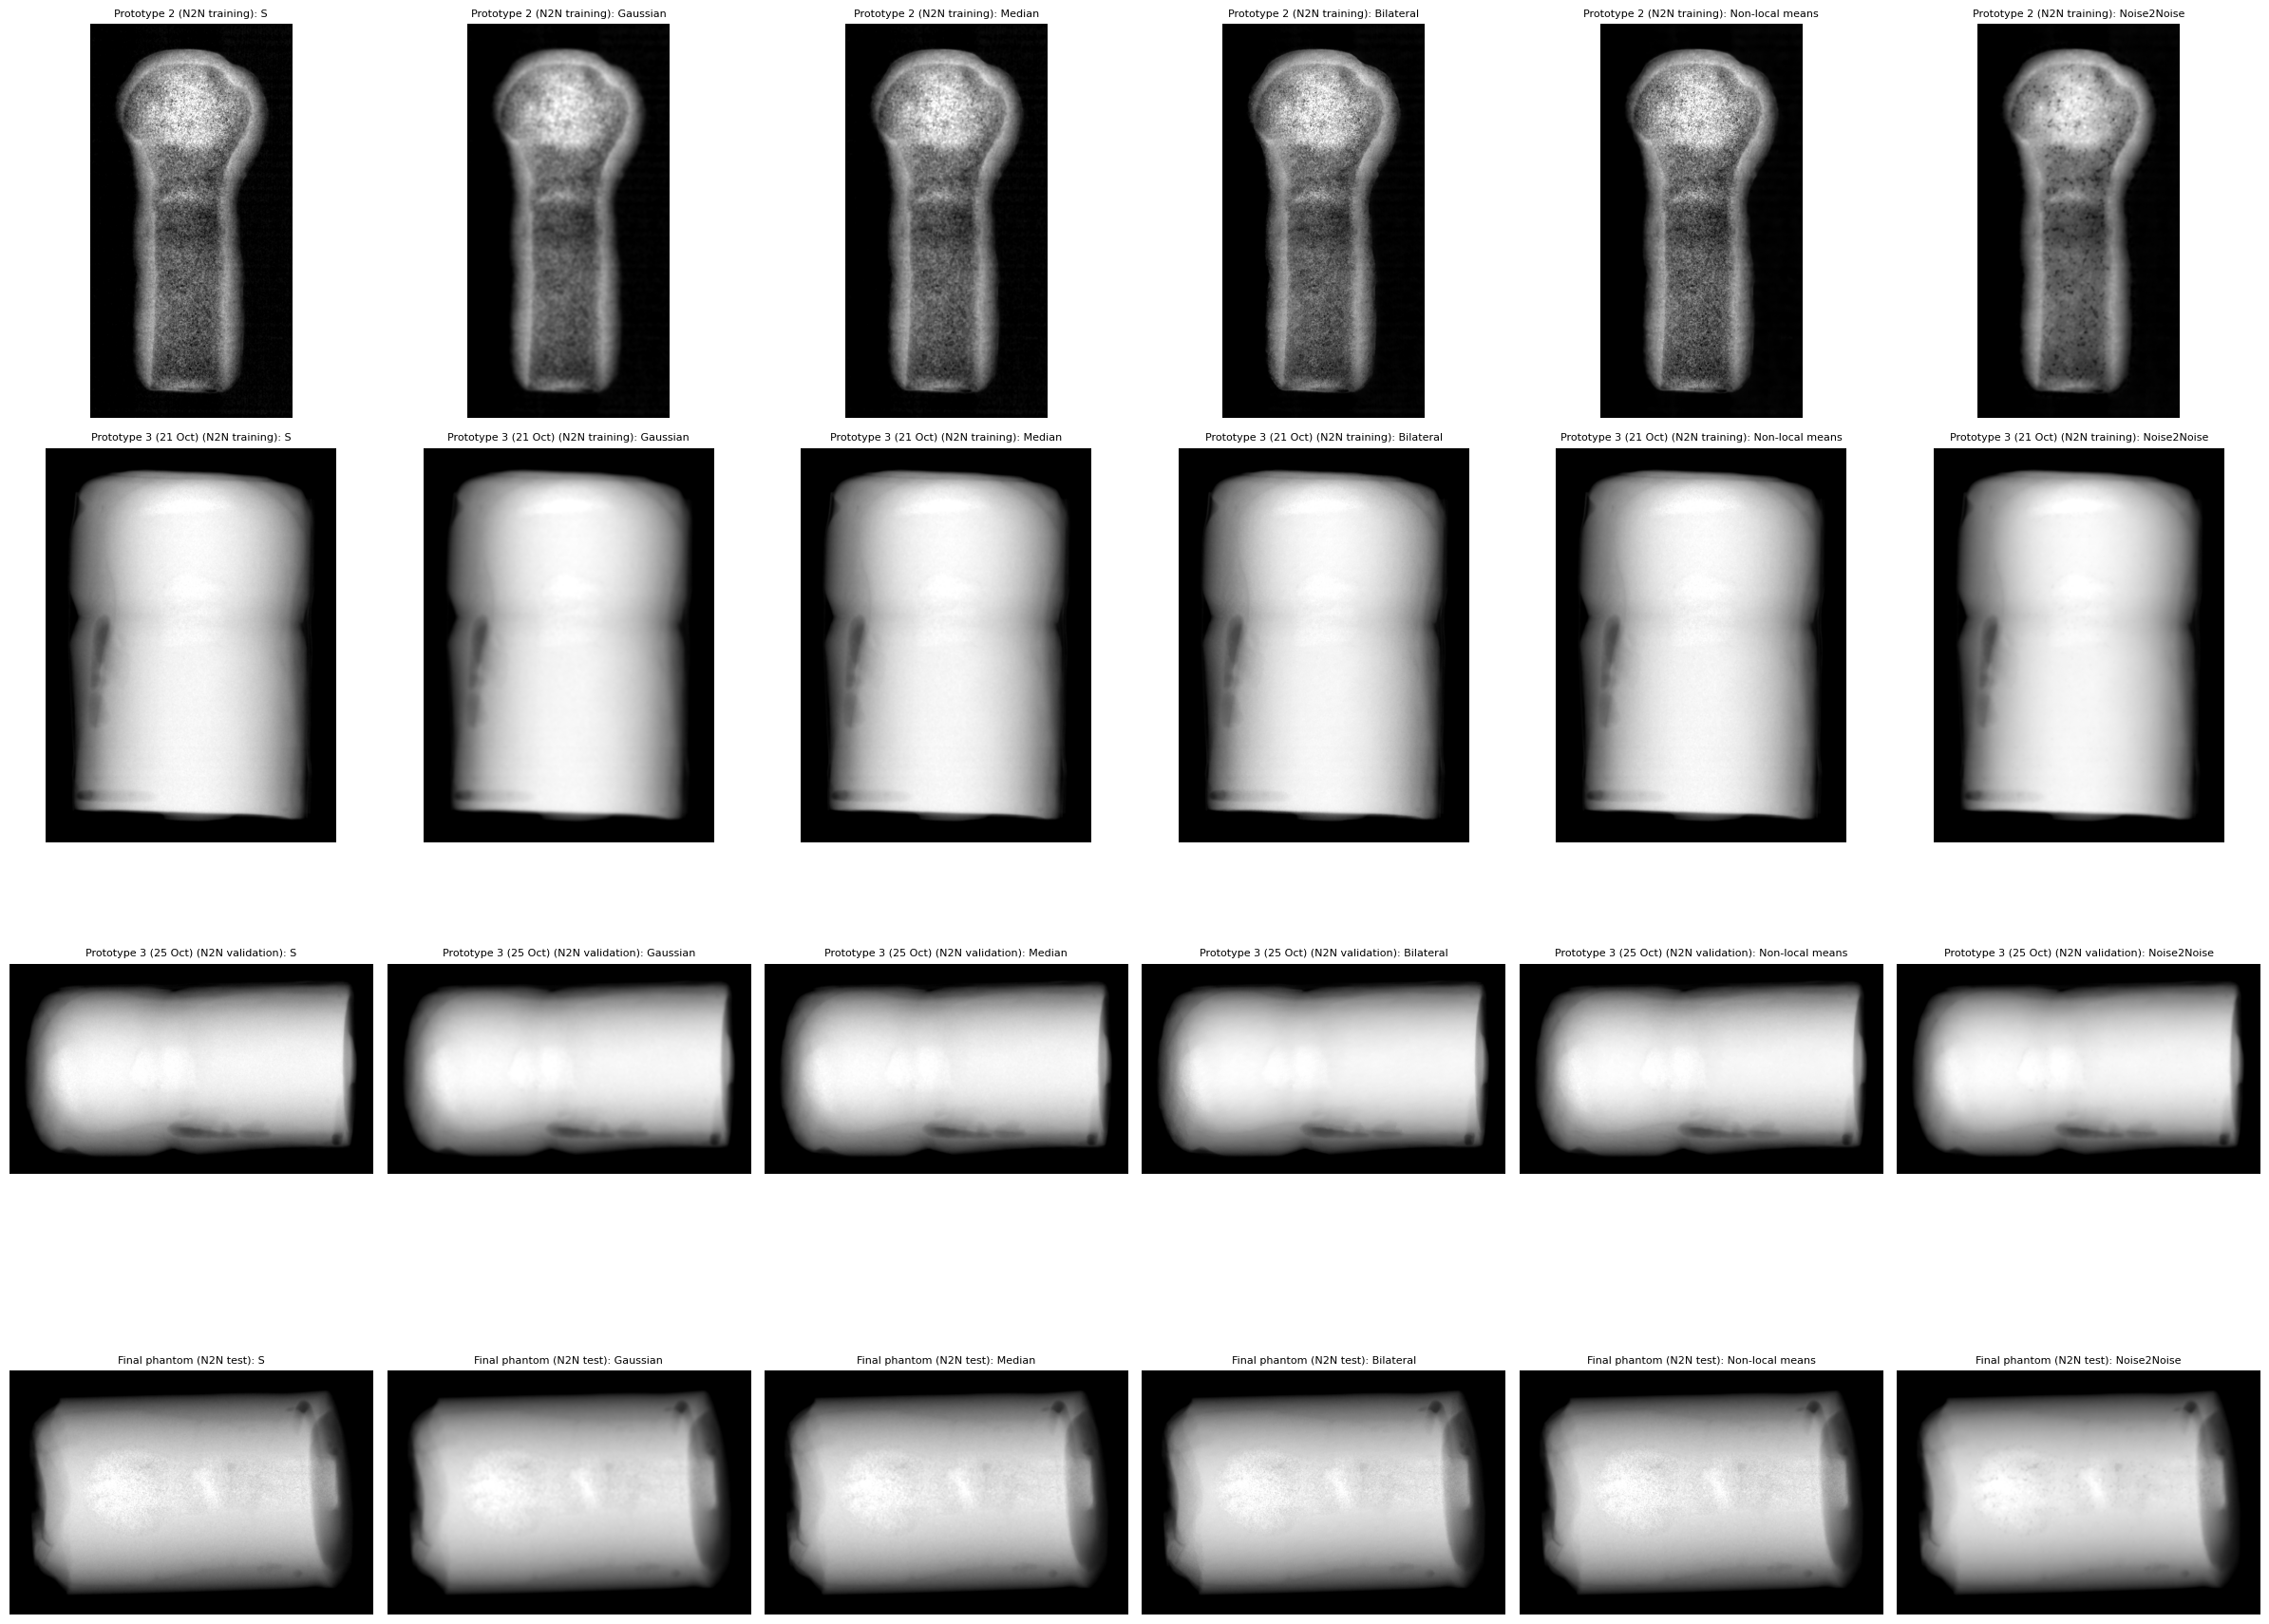

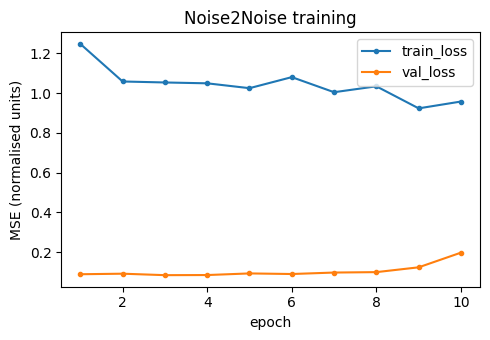

In [7]:
# ========================================================================================================

# Phase 6: Denoising

"""Noise suppression of the bone-suppressed images S (Modules/Denoising.py), in cm of PLA so the same ROIs measure them.
1. Noise model: the lag-one autocorrelation of the noise in the background band picks the learning-based method (both
   directions correlated -> Noise2Noise; the blind-spot methods need uncorrelated noise).
2. Classical filters at medium strength: Gaussian, median, bilateral and non-local means.
3. Noise2Noise: needs no clean image, only a second, independent noisy image of the same scene, S2 from the repeat scans
   (registered onto S, calibrated with the same wedge, subtracted with the same weights). Trained on the two prototypes of
   21 October, its epoch chosen on prototype 3 rescanned on 25 October (the session of the final phantom), tested on the final
   phantom. Training takes several minutes on the CPU; the network is saved and reloaded (RETRAIN_N2N = True trains again).
Every filter is judged by max |delta mu| (largest change of an ROI median, should be close to 0), the noise reduction in the
background band and the change of the phantom's edge width (blur). On 25 October the background holds a fixed column pattern
of the detector that is the same in every scan, so it is not noise and no filter removes it. The test on the final phantom
therefore uses the repeat scan: the filter whose output comes closest to the independent S2 is the closest to the clean image,
counting noise left and detail lost alike (Denoising.repeat_difference), in the bone and in the soft tissue separately. The
final phantom's bone is about 17 cm of PLA at 60 kVp, so few photons reach the detector behind it and S is about five times
noisier there than in the soft tissue; the bilateral and non-local means filters take their strength from the background
noise, so they leave that noise in place."""

# 1. Noise model selection
for name, s in suppressed.items():
    rho_x, rho_y = Denoising.noise_autocorrelation(s['S'], masks[name].roi('Phantom background'))
    print(f"{name}: rho_x = {rho_x:.2f}, rho_y = {rho_y:.2f} -> {Denoising.select_model(rho_x, rho_y)}")

# 2. Classical filters (medium strength)
def phantom_metrics(name, image):
    p = phantoms[name]
    return Denoising.image_metrics(image, masks[name].rois, list(p['bones'].items()) + list(p['soft'].items()), bg,
                                   masks[name].footprint, pixel_spacing, trend=p.get('trend'))

original = {name: phantom_metrics(name, s['S']) for name, s in suppressed.items()}
denoised = {name: {f: Denoising.classical_filter(s['S'], f, 1, original[name]['sigma_bg']) for f in Denoising.FILTER_SETTINGS}
            for name, s in suppressed.items()}

# 3. Noise2Noise
RETRAIN_N2N = False
model_path = os.path.join(output_folder, 'noise2noise.pt')
TRAIN, VALIDATION, TEST = ['Prototype 2', 'Prototype 3 (21 Oct)'], ['Prototype 3 (25 Oct)'], 'Final phantom'

# The repeat scans, registered onto the main pair at the same kVp (same grey levels, so the plain MSE is used)
repeat = {}
for name, region in regions.items():
    s = sessions[region_session[name]]
    repeat[name] = {}
    for k, reference in [('low', targets[name]), ('high', aligned[name])]:
        moving = region.crop(ready_img(s['images'][f'repeat_{k}']))
        (theta, tx, ty), _ = Affine_matrix.register(reference, moving, [0, 0, 0])
        repeat[name][k] = Affine_matrix.transformation(moving, theta, tx, ty)
repeat_calibration = {session: {k: Wedge_calibration.Wedge_Calibration(repeat[box][k], wedges[session]) for k in ('low', 'high')}
                      for session, box in wedge_box.items()}

def second_realisation(name):
    """S2 of a phantom from its repeat pair, subtracted exactly as S."""
    mask, sweep, rcal = masks[name], sweeps[name], repeat_calibration[region_session[name]]
    T = {k: rcal[k].linear_thickness_map(repeat[name][k], np.median(repeat[name][k][mask.roi(bg)])) for k in ('low', 'high')}
    S2 = T['high'] - suppressed[name]['w'] * T['low']
    if name == 'Final phantom':                                 # the same per-part bone weights as S
        B_L = np.where(ndi.binary_dilation(final.bone, iterations=int(round(1 / pixel_spacing))),
                       T['low'] - final.soft_tissue_trend(T['low']), 0.0)
        S2 = S2 - np.nan_to_num((suppressed[name]['w_part'] - suppressed[name]['w']) * B_L)
    return S2

pairs = {}
for name, s in suppressed.items():
    ok = np.zeros(s['S'].shape, bool)
    ok[10:-10, 10:-10] = True                                   # registration fills the image edges
    pairs[name] = Denoising.align_pair(s['S'], second_realisation(name), ok)

if os.path.exists(model_path) and not RETRAIN_N2N:
    n2n = Denoising.Noise2Noise.load(model_path)
    print(f"Noise2Noise network loaded from {model_path}")
else:
    n2n = Denoising.Noise2Noise()
    n2n.fit([p for n in TRAIN for p in pairs[n]], [p for n in VALIDATION for p in pairs[n]])
    n2n.save(model_path)
for name, s in suppressed.items():
    denoised[name]['Noise2Noise'] = n2n.predict(s['S'])

# 4. Results
role = {**{n: 'N2N training' for n in TRAIN}, **{n: 'N2N validation' for n in VALIDATION}, TEST: 'N2N test'}
table = pd.DataFrame([{'phantom': name, 'role': role[name], **Denoising.compare(original[name], phantom_metrics(name, image), f)}
                      for name, images_ in denoised.items() for f, image in images_.items()]).set_index(['phantom', 'filter'])
display(table[['role', 'max_abs_delta_mu', 'noise_reduction_pct', 'edge_change_mm']].round(3))
table.to_csv(os.path.join(output_folder, 'denoising_metrics.csv'))

S1, S2, ok = pairs[TEST][0]
inside = ok & ndi.binary_erosion(final.footprint, iterations=int(round(3 / pixel_spacing)))
regions_ = {'bone': inside & (final.roi('Bone shaft') | final.roi('Bone head')),
            'soft tissue': inside & (final.roi('Muscle') | final.roi('Fat'))}
test = pd.DataFrame([{'filter': f, **{f'RMS difference to S2, {r} (cm PLA)': Denoising.repeat_difference(image, S2, m)
                                       for r, m in regions_.items()}}
                     for f, image in [('S (unfiltered)', S1)] + list(denoised[TEST].items())]).set_index('filter')
for r in regions_:
    c = f'RMS difference to S2, {r} (cm PLA)'
    test[f'reduction, {r} (%)'] = 100 * (1 - test[c] / test.loc['S (unfiltered)', c])
print("Test on the final phantom: RMS difference to its independent repeat scan (lower is better):")
display(test.round(4))
test.to_csv(os.path.join(output_folder, 'denoising_test_final_phantom.csv'))
for name, images_ in denoised.items():
    np.savez_compressed(os.path.join(output_folder, f"denoised_{name.replace(' ', '_').replace('(', '').replace(')', '')}.npz"),
                        **{f.replace(' ', '_').replace('-', '_'): image for f, image in images_.items()})

fig, axes = plt.subplots(len(suppressed), 6, figsize=(24, 4.5 * len(suppressed)))
for row, (name, s) in zip(axes, suppressed.items()):
    rr, cc = np.nonzero(masks[name].footprint)
    pad = int(round(10 / pixel_spacing))
    window = (slice(max(rr.min() - pad, 0), rr.max() + pad), slice(max(cc.min() - pad, 0), cc.max() + pad))
    vmin, vmax = np.percentile(s['S'][masks[name].footprint], [1, 99])
    for ax, (label, image) in zip(row, [('S', s['S'])] + list(denoised[name].items())):
        ax.imshow(image[window], cmap='gray', vmin=vmin, vmax=vmax)
        ax.set_title(f'{name} ({role[name]}): {label}', fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 3.5))
pd.DataFrame(n2n.history, columns=['epoch', 'train_loss', 'val_loss']).set_index('epoch').plot(ax=ax, marker='o', ms=3)
ax.set_ylabel('MSE (normalised units)')
ax.set_title('Noise2Noise training')
plt.tight_layout()
plt.show()

## Validation

The final phantom is validated in two steps:

1. **SNR and CNR** of the final phantom before bone suppression ($T_L$, $T_H$) and after it ($S$, and $S$ after Noise2Noise).
2. **Side by side with open-source radiographs**: the final phantom next to three conventional radiographs of a real left humerus (Kaggle humerus fracture dataset, non-fractured originals, CC BY 4.0).

,SNR bone,SNR soft tissue,CNR bone / soft tissue,CNR soft tissue / background,background sigma (cm PLA)
image,,,,,
T_L (60 kVp),454.82,155.13,186.57,155.13,0.04
T_H (120 kVp),394.46,165.88,110.00,165.88,0.04
S (bone suppressed),216.46,128.41,0.10,128.26,0.02
"S, Noise2Noise",272.65,161.19,0.55,161.11,0.02


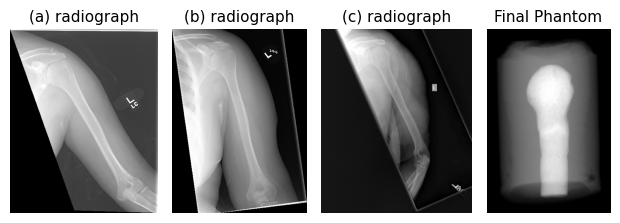

In [8]:
# ========================================================================================================

# Phase 7: Validation

"""1. SNR and CNR (eq. metrics): SNR = ROI median / standard deviation of the background band, CNR = |difference of two
   medians| / the same standard deviation. Bone: the shaft and head ROIs, measured against the soft tissue under them (as in
   Phase 5); soft tissue: the muscle and fat ROIs, measured against the background. Each value is the mean over the ROIs.
2. The final phantom at 60 kVp (the closest to a conventional humerus exposure), turned so the head is at the top, next to
   three radiographs of a left humerus (L marker, scapula on the viewer's left of the head). The radiographs are processed
   8-bit images from other systems, so the comparison is visual only. The figure is drawn at the report's text width
   (6.3 in), so its labels print at their set size, and saved as a PDF as well."""

name = 'Final phantom'
p = phantoms[name]
images_ = {'T_L (60 kVp)': thickness_maps[name]['low'], 'T_H (120 kVp)': thickness_maps[name]['high'],
           'S (bone suppressed)': suppressed[name]['S'], 'S, Noise2Noise': denoised[name]['Noise2Noise']}
metrics = Validation.metrics_table(images_, final.rois, list(p['bones'].items()) + list(p['soft'].items()), bg,
                                   trend=p['trend'])
summary = pd.DataFrame({
    'SNR bone': metrics[[f'SNR {r}' for r in p['bones']]].mean(axis=1),
    'SNR soft tissue': metrics[[f'SNR {r}' for r in p['soft']]].mean(axis=1),
    'CNR bone / soft tissue': metrics[[f'CNR {a} / {b}' for a, b in p['bones'].items()]].mean(axis=1),
    'CNR soft tissue / background': metrics[[f'CNR {a} / {b}' for a, b in p['soft'].items()]].mean(axis=1),
    'background sigma (cm PLA)': metrics['sigma_bg']})
display(summary.round(2))
summary.to_csv(os.path.join(output_folder, 'validation_snr_cnr.csv'))

# 2. Side by side with left humerus radiographs
humerus_folder = os.path.join('..', 'Open Source Images', 'Humerus fractures (Kaggle)', 'no fracturados')
humerus_files = ['image1 (214).png', 'image2 (122).png', 'image2 (160).png']
for f in humerus_files:                                         # downloaded on the first run
    Validation.kaggle_file(Validation.HUMERUS, f'original_data/original_data/no fracturados/{f}', os.path.join(humerus_folder, f))

rr, cc = np.nonzero(final.footprint)
pad = int(round(10 / pixel_spacing))
window = (slice(max(rr.min() - pad, 0), rr.max() + pad), slice(max(cc.min() - pad, 0), cc.max() + pad))
upright = lambda image: np.rot90(image[window], -1)            # head (left) to the top
panels = [(f'({letter}) radiograph', Validation.load_grey(os.path.join(humerus_folder, f)))
          for letter, f in zip('abc', humerus_files)] + [('Final Phantom', upright(thickness_maps[name]['low']))]
widths = [image.shape[1] / image.shape[0] for _, image in panels]   # equal heights, no image squashed
fig, axes = plt.subplots(1, len(panels), figsize=(6.3, 6.3 / sum(widths) + 0.4), gridspec_kw={'width_ratios': widths})
for ax, (label, image) in zip(axes, panels):
    ax.imshow(image, cmap='gray', vmin=np.percentile(image, 1), vmax=np.percentile(image, 99.5))
    ax.set_title(label, fontsize=11)
    ax.axis('off')
plt.tight_layout()
for ext in ('pdf', 'png'):
    fig.savefig(os.path.join(output_folder, f'validation_side_by_side.{ext}'), dpi=300, bbox_inches='tight')
plt.show()